In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import seaborn as sns

In [20]:
x,y=make_moons(n_samples=1000,noise=0.2)

In [21]:
df= {"x1":x[:,0],"x2":x[:,-1],"y":y}

In [22]:
dataset=pd.DataFrame(df)

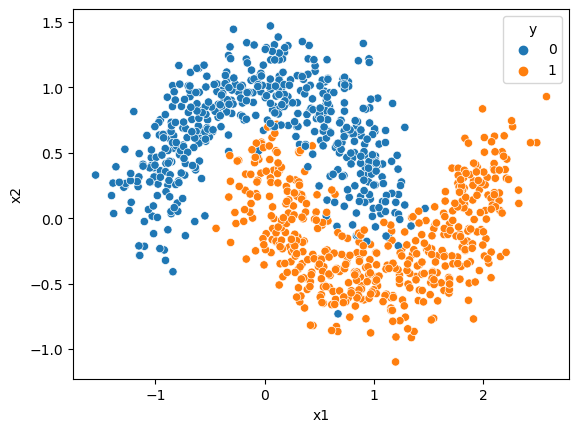

In [23]:
sns.scatterplot(x="x1",y="x2",data=dataset,hue="y")
plt.show()

In [28]:
x=dataset[["x1","x2"]]
y=dataset[["y"]]


In [29]:
from sklearn.model_selection import train_test_split

In [30]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB


In [35]:
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)
dt.score(x_train,y_train)*100,dt.score(x_test,y_test)*100

(100.0, 97.5)

In [36]:
svm=SVC()
svm.fit(x_train,y_train)
svm.score(x_train,y_train)*100,svm.score(x_test,y_test)*100

C:\Users\Suchana\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


(96.5, 98.0)

In [37]:
gnb=GaussianNB()
gnb.fit(x_train,y_train)
gnb.score(x_train,y_train)*100,gnb.score(x_test,y_test)*100

C:\Users\Suchana\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


(87.0, 85.5)

In [38]:
from sklearn.ensemble import VotingClassifier

In [39]:
li=[("dt1",DecisionTreeClassifier()),("svm1",SVC()),("gnb1",GaussianNB())]

In [44]:
vc=VotingClassifier(li,weights=[1.5,1,0.5])
vc.fit(x_train,y_train)

C:\Users\Suchana\anaconda3\Lib\site-packages\sklearn\preprocessing\_label.py:99: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\Suchana\anaconda3\Lib\site-packages\sklearn\preprocessing\_label.py:134: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


VotingClassifier(estimators=[('dt1', DecisionTreeClassifier()), ('svm1', SVC()),
                             ('gnb1', GaussianNB())],
                 weights=[1.5, 1, 0.5])

In [45]:
vc.score(x_train,y_train)*100,vc.score(x_test,y_test)*100

(99.25, 97.5)